# Analisis Komparasi Spasial & Temporal: CHIRPS v3 SAT vs RNL
Notebook ini didesain khusus untuk menganalisis dan membandingkan secara langsung dua varian **CHIRPS v3.0** di Kabupaten Kebumen:
1. **CHIRPS v3 SAT (Satellite-based):** Estimasi curah hujan berbasis observasi satelit inframerah CCD.
2. **CHIRPS v3 RNL (Reanalysis-assisted):** Estimasi curah hujan dengan asimilasi latar belakang model reanalisis atmosfer.

### Fitur Utama:
- **Dual Compatibility:** Otomatis membaca path dataset lokal maupun Kaggle Input (`/kaggle/input/datasets/jerismeteo/`).
- **Side-by-Side Visualizations:** Grafik perbandingan berdampingan (Kiri: SAT vs Kanan: RNL) dan peta selisih spasial (SAT - RNL).
- **Statistik Validasi & Korelasi:** $R^2$, Korelasi Pearson, RMSE, MAE, dan Bias.
- **Peta Spasial Bulanan Diskret:** Visualisasi resolusi tinggi dengan batas administratif kecamatan Kebumen.

In [1]:
import os
import glob
import xarray as xr
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from pathlib import Path
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = "DejaVu Sans"
plt.rcParams['font.family'] = "sans-serif"

# ==========================================
# 0. PENGATURAN PATH & PERIODE WAKTU DINAMIS
# ==========================================
IS_KAGGLE = 'KAGGLE_KERNEL_RUN_TYPE' in os.environ

if IS_KAGGLE:
    # Di Kaggle: Gunakan seluruh data yang diunduh GEE_CHIRPS (2000 - 2026)
    tahun_filter_mulai = None
    base_input = Path("/kaggle/input/datasets/jerismeteo")
    
    # Path CHIRPS SAT
    if (base_input / "gee-chirps-kebumen/data/chirps_sat").exists():
        dir_sat = base_input / "gee-chirps-kebumen/data/chirps_sat"
    elif (base_input / "gee-chirps-kebumen/data/chirps").exists():
        dir_sat = base_input / "gee-chirps-kebumen/data/chirps"
    elif Path("/kaggle/working/data/chirps_sat").exists():
        dir_sat = Path("/kaggle/working/data/chirps_sat")
    elif Path("/kaggle/working/data/chirps").exists():
        dir_sat = Path("/kaggle/working/data/chirps")
    else:
        found = glob.glob("/kaggle/input/**/chirps*sat*", recursive=True)
        dir_sat = Path(found[0]) if found else Path("data/chirps_sat")
        
    # Path CHIRPS RNL
    if (base_input / "gee-chirps-kebumen/data/chirps_rnl").exists():
        dir_rnl = base_input / "gee-chirps-kebumen/data/chirps_rnl"
    elif Path("/kaggle/working/data/chirps_rnl").exists():
        dir_rnl = Path("/kaggle/working/data/chirps_rnl")
    else:
        found = glob.glob("/kaggle/input/**/chirps*rnl*", recursive=True)
        dir_rnl = Path(found[0]) if found else Path("data/chirps_rnl")
        
    # Path GeoJSON
    kaggle_geo = base_input / "projek-downscale/33.05_kecamatan.geojson"
    geojson_path = str(kaggle_geo) if kaggle_geo.exists() else glob.glob("/kaggle/input/**/33.05_kecamatan.geojson", recursive=True)[0]
    out_dir = Path("/kaggle/working/chirps_komparasi")
else:
    # Di Lokal: Analisis fokus dari tahun 2020 ke depan (2020 - 2026)
    tahun_filter_mulai = '2020-01-01'
    dir_sat = Path("data/chirps_sat") if Path("data/chirps_sat").exists() else Path("data/chirps")
    dir_rnl = Path("data/chirps_rnl")
    geojson_path = "33.05_kecamatan.geojson"
    out_dir = Path("chirps_komparasi")

out_dir.mkdir(parents=True, exist_ok=True)
print(f"📌 Environment           : {'Kaggle' if IS_KAGGLE else 'Lokal'}")
print(f"📌 Periode Analisis      : {'Semua Data GEE (2000 - 2026)' if IS_KAGGLE else '2020 s.d. Sekarang'}")
print(f"📌 Direktori CHIRPS SAT  : {dir_sat}")
print(f"📌 Direktori CHIRPS RNL  : {dir_rnl}")
print(f"📌 Lokasi File GeoJSON   : {geojson_path}")
print(f"📌 Folder Output Hasil   : {out_dir}")


📌 Environment           : Kaggle
📌 Periode Analisis      : Semua Data GEE (2000 - 2026)
📌 Direktori CHIRPS SAT  : /kaggle/input/datasets/jerismeteo/gee-chirps-kebumen/data/chirps_sat
📌 Direktori CHIRPS RNL  : /kaggle/input/datasets/jerismeteo/gee-chirps-kebumen/data/chirps_rnl
📌 Lokasi File GeoJSON   : /kaggle/input/datasets/jerismeteo/projek-downscale/33.05_kecamatan.geojson
📌 Folder Output Hasil   : /kaggle/working/chirps_komparasi


## 1. Memuat & Menyelaraskan Dataset NetCDF (SAT & RNL)
Membuka file NetCDF untuk kedua varian dan menyelaraskan rentang waktu (*time alignment*).

In [2]:
files_sat = sorted(list(dir_sat.glob("**/*.nc")))
files_rnl = sorted(list(dir_rnl.glob("**/*.nc")))

print(f"Total file CHIRPS SAT ditemukan : {len(files_sat)}")
print(f"Total file CHIRPS RNL ditemukan : {len(files_rnl)}")

if not files_sat:
    raise FileNotFoundError(f"File NetCDF SAT tidak ditemukan di: {dir_sat}")

ds_sat_raw = xr.open_mfdataset(files_sat, combine='by_coords')

has_rnl = len(files_rnl) > 0
if has_rnl:
    ds_rnl_raw = xr.open_mfdataset(files_rnl, combine='by_coords')
    ds_sat_raw, ds_rnl_raw = xr.align(ds_sat_raw, ds_rnl_raw, join='inner')
    print("\n✅ Berhasil menyelaraskan koordinat waktu SAT & RNL!")
else:
    print("\nℹ️ Data RNL belum tersedia, visualisasi akan fokus pada SAT.")

# Terapkan filter waktu jika di lokal (2020 ke depan)
if tahun_filter_mulai:
    ds_sat = ds_sat_raw.sel(time=slice(tahun_filter_mulai, None))
    if has_rnl:
        ds_rnl = ds_rnl_raw.sel(time=slice(tahun_filter_mulai, None))
    print(f"\n🔍 Data difilter untuk periode Lokal: {tahun_filter_mulai} s.d. selesai")
else:
    ds_sat = ds_sat_raw
    if has_rnl:
        ds_rnl = ds_rnl_raw
    print("\n🔍 Menggunakan seluruh rentang data Kaggle GEE")

print("\n--- Informasi Dataset CHIRPS SAT yang Dianalisis ---")
print(ds_sat)


Total file CHIRPS SAT ditemukan : 319
Total file CHIRPS RNL ditemukan : 319


/tmp/ipykernel_16/1705188226.py:10: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_sat_raw = xr.open_mfdataset(files_sat, combine='by_coords')
/tmp/ipykernel_16/1705188226.py:14: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds_rnl_raw = xr.open_mfdataset(files_rnl, combine='by_coords')



✅ Berhasil menyelaraskan koordinat waktu SAT & RNL!

🔍 Menggunakan seluruh rentang data Kaggle GEE

--- Informasi Dataset CHIRPS SAT yang Dianalisis ---
<xarray.Dataset> Size: 4MB
Dimensions:        (time: 9709, y: 9, x: 10)
Coordinates:
  * time           (time) datetime64[ns] 78kB 2000-01-01 ... 2026-07-31
  * y              (y) float64 72B -7.425 -7.475 -7.525 ... -7.725 -7.775 -7.825
  * x              (x) float64 80B 109.4 109.4 109.5 109.5 ... 109.7 109.8 109.8
Data variables:
    spatial_ref    (time) int64 78kB 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0
    precipitation  (time, y, x) float32 3MB dask.array<chunksize=(31, 9, 10), meta=np.ndarray>


## 2. Memuat Peta Vektor Wilayah (GeoJSON Kecamatan Kebumen)

In [3]:
gdf_kec = gpd.read_file(geojson_path)
if gdf_kec.crs != "EPSG:4326":
    gdf_kec = gdf_kec.to_crs("EPSG:4326")

print(f"Berhasil memuat GeoJSON: {len(gdf_kec)} Kecamatan di Kebumen")
gdf_kec.head(3)

Berhasil memuat GeoJSON: 26 Kecamatan di Kebumen


,kd_propinsi,kd_dati2,kd_kecamatan,nm_kecamatan,geometry
0,33,05,001,Ayah,"MULTIPOLYGON Z (((109.41096 -7.77624 0, 109.41..."
1,33,05,002,Buayan,"MULTIPOLYGON Z (((109.46888 -7.75906 0, 109.46..."
2,33,05,003,Puring,"MULTIPOLYGON Z (((109.5242 -7.76568 0, 109.524..."


## 3. Ekstraksi Deret Waktu Rata-rata Wilayah (Areal Mean) & Metrik Statistik

In [4]:
spatial_dims = [dim for dim in ds_sat['precipitation'].dims if dim != 'time']

series_sat = ds_sat['precipitation'].mean(dim=spatial_dims).to_series()
df_daily = pd.DataFrame({'SAT': series_sat})

if has_rnl:
    series_rnl = ds_rnl['precipitation'].mean(dim=spatial_dims).to_series()
    df_daily['RNL'] = series_rnl
    df_daily['Diff (SAT-RNL)'] = df_daily['SAT'] - df_daily['RNL']

df_daily.index.name = 'DateTime'
df_monthly = df_daily.resample('ME').sum()
df_annual = df_daily.resample('YE').sum()

print("Statistik Deskriptif Curah Hujan Harian:")
print(df_daily.describe())

if has_rnl:
    r_val, p_val = pearsonr(df_daily['SAT'], df_daily['RNL'])
    rmse = np.sqrt(mean_squared_error(df_daily['SAT'], df_daily['RNL']))
    mae = mean_absolute_error(df_daily['SAT'], df_daily['RNL'])
    r2 = r2_score(df_daily['SAT'], df_daily['RNL'])
    bias = np.mean(df_daily['Diff (SAT-RNL)'])
    
    print(f"\n{'='*50}")
    print(f"METRIK VALIDASI KOMPARASI (SAT vs RNL):")
    print(f"  • Koefisien Korelasi (r) : {r_val:.4f} (p-val: {p_val:.2e})")
    print(f"  • Determinasi (R²)       : {r2:.4f}")
    print(f"  • RMSE                   : {rmse:.4f} mm/hari")
    print(f"  • MAE                    : {mae:.4f} mm/hari")
    print(f"  • Mean Bias (SAT - RNL)  : {bias:.4f} mm/hari")
    print(f"{'='*50}")

Statistik Deskriptif Curah Hujan Harian:
               SAT          RNL  Diff (SAT-RNL)
count  9709.000000  9709.000000    9.709000e+03
mean      9.036945     9.036945    4.862177e-09
std      12.811924    10.785444    8.772748e+00
min       0.000000     0.000000   -6.593570e+01
25%       0.584769     1.210774   -2.994879e+00
50%       3.348728     5.240750   -2.047430e-01
75%      12.938756    13.125078    1.767893e+00
max     128.704239   100.043541    8.986624e+01

METRIK VALIDASI KOMPARASI (SAT vs RNL):
  • Koefisien Korelasi (r) : 0.7364 (p-val: 0.00e+00)
  • Determinasi (R²)       : 0.5311
  • RMSE                   : 8.7723 mm/hari
  • MAE                    : 5.1456 mm/hari
  • Mean Bias (SAT - RNL)  : 0.0000 mm/hari


## 4. Visualisasi Time Series Komparasi (Kiri: SAT vs Kanan: RNL / Overlaid)

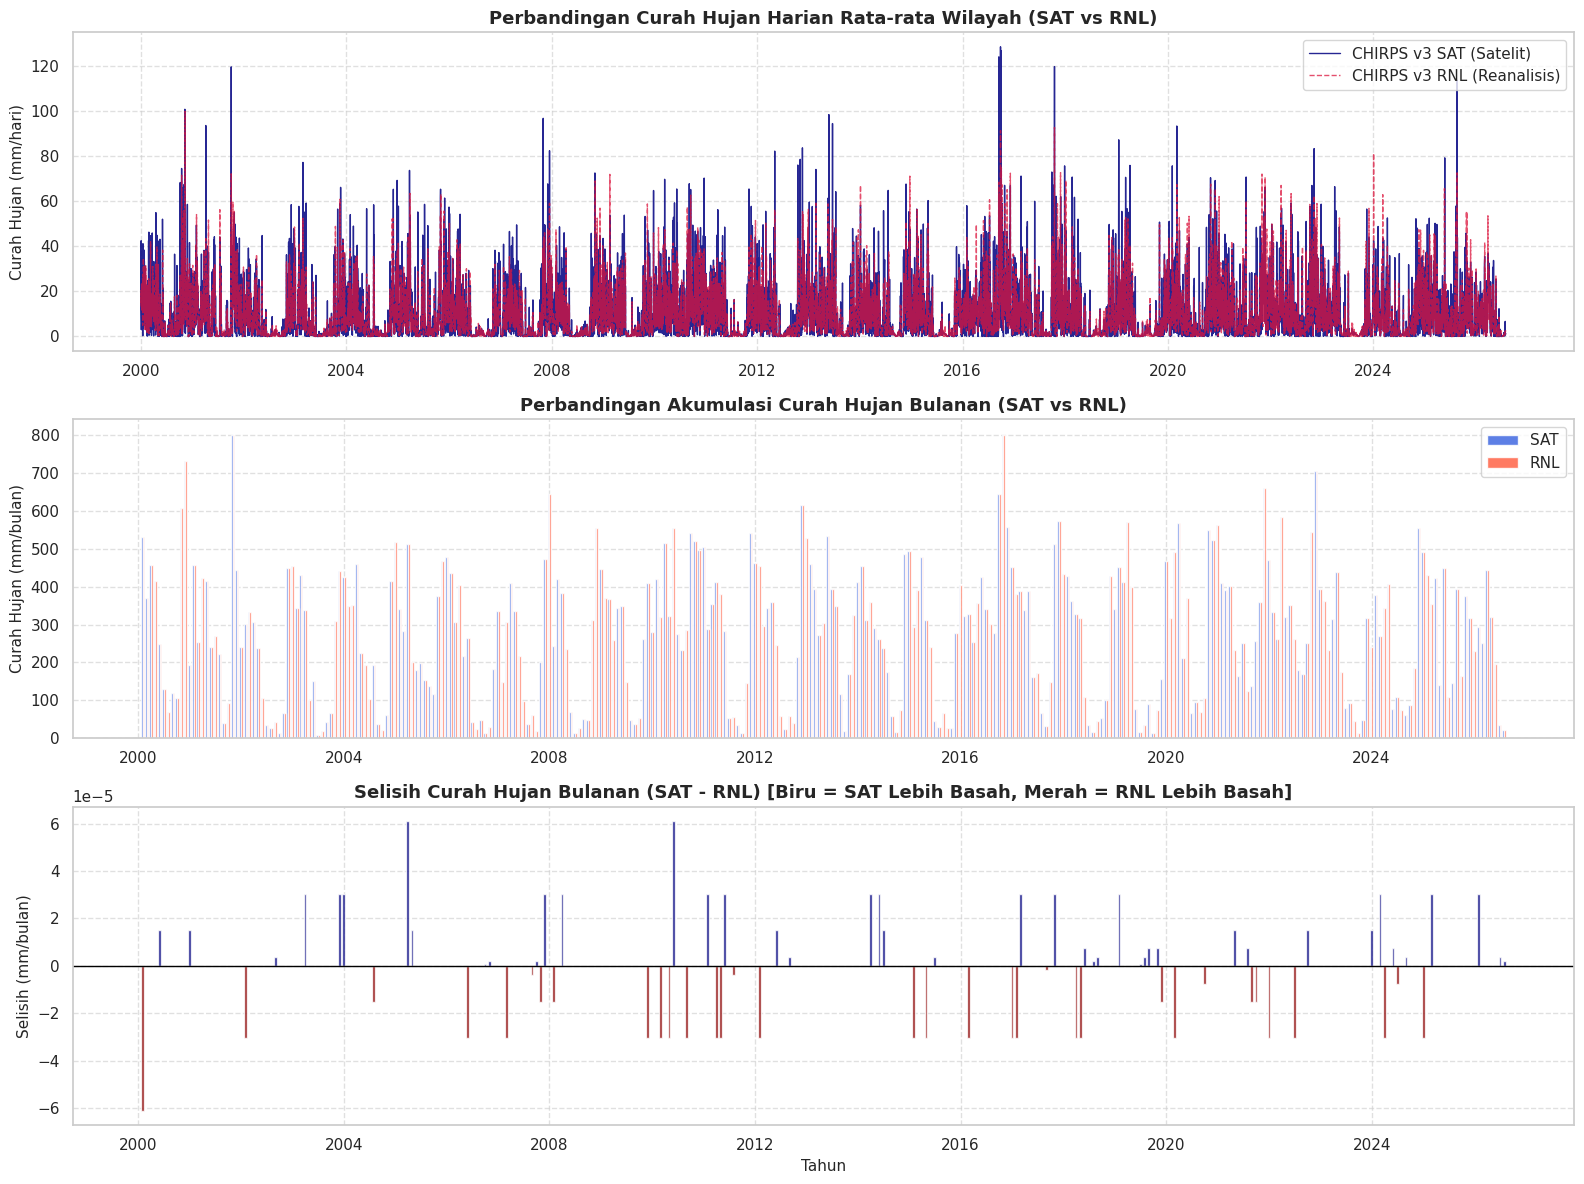

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=False)

# 1. Plot Harian Overlaid
axes[0].plot(df_daily.index, df_daily['SAT'], label='CHIRPS v3 SAT (Satelit)', color='navy', lw=1, alpha=0.85)
if has_rnl:
    axes[0].plot(df_daily.index, df_daily['RNL'], label='CHIRPS v3 RNL (Reanalisis)', color='crimson', lw=1, alpha=0.75, linestyle='--')
axes[0].set_title("Perbandingan Curah Hujan Harian Rata-rata Wilayah (SAT vs RNL)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("Curah Hujan (mm/hari)", fontsize=11)
axes[0].legend(loc='upper right', frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Plot Akumulasi Bulanan Berdampingan
width = 12
axes[1].bar(df_monthly.index - pd.Timedelta(days=6), df_monthly['SAT'], width=width, label='SAT', color='royalblue', alpha=0.85)
if has_rnl:
    axes[1].bar(df_monthly.index + pd.Timedelta(days=6), df_monthly['RNL'], width=width, label='RNL', color='tomato', alpha=0.85)
axes[1].set_title("Perbandingan Akumulasi Curah Hujan Bulanan (SAT vs RNL)", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Curah Hujan (mm/bulan)", fontsize=11)
axes[1].legend(loc='upper right', frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.6)

# 3. Plot Selisih Bulanan (SAT - RNL)
if has_rnl:
    diff_monthly = df_monthly['SAT'] - df_monthly['RNL']
    colors = ['navy' if val >= 0 else 'darkred' for val in diff_monthly]
    axes[2].bar(df_monthly.index, diff_monthly, width=20, color=colors, alpha=0.8)
    axes[2].axhline(0, color='black', lw=1)
    axes[2].set_title("Selisih Curah Hujan Bulanan (SAT - RNL) [Biru = SAT Lebih Basah, Merah = RNL Lebih Basah]", fontsize=13, fontweight='bold')
    axes[2].set_ylabel("Selisih (mm/bulan)", fontsize=11)
    axes[2].set_xlabel("Tahun", fontsize=11)
    axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig(out_dir / "komparasi_timeseries_sat_vs_rnl.png", dpi=300, bbox_inches='tight')
plt.show()

## 5. Scatter Plot & Korelasi Komparasi (SAT vs RNL)

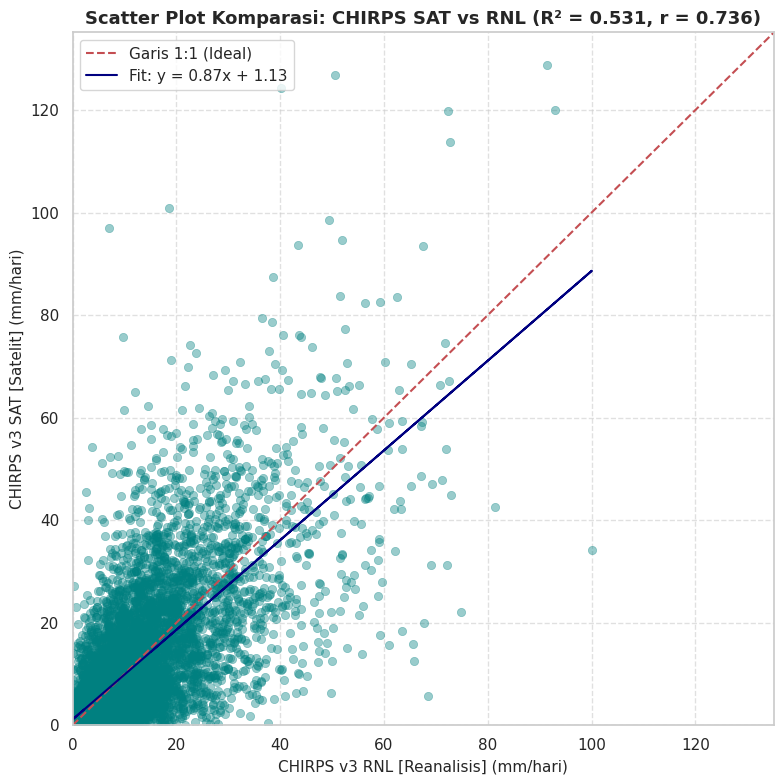

In [6]:
if has_rnl:
    fig, ax = plt.subplots(figsize=(8, 8))
    max_val = max(df_daily['SAT'].max(), df_daily['RNL'].max()) * 1.05
    
    sns.scatterplot(data=df_daily, x='RNL', y='SAT', alpha=0.4, color='teal', edgecolor=None, ax=ax)
    ax.plot([0, max_val], [0, max_val], 'r--', lw=1.5, label='Garis 1:1 (Ideal)')
    
    # Garis Regresi Linier
    m_slope, b_intercept = np.polyfit(df_daily['RNL'], df_daily['SAT'], 1)
    ax.plot(df_daily['RNL'], m_slope * df_daily['RNL'] + b_intercept, color='navy', lw=1.5, label=f'Fit: y = {m_slope:.2f}x + {b_intercept:.2f}')
    
    ax.set_title(f"Scatter Plot Komparasi: CHIRPS SAT vs RNL (R² = {r2:.3f}, r = {r_val:.3f})", fontsize=13, fontweight='bold')
    ax.set_xlabel("CHIRPS v3 RNL [Reanalisis] (mm/hari)", fontsize=11)
    ax.set_ylabel("CHIRPS v3 SAT [Satelit] (mm/hari)", fontsize=11)
    ax.set_xlim(0, max_val)
    ax.set_ylim(0, max_val)
    ax.legend(loc='upper left', frameon=True)
    ax.grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.savefig(out_dir / "scatter_sat_vs_rnl.png", dpi=300, bbox_inches='tight')
    plt.show()

## 6. Komparasi Pola Siklus Klimatologi Bulanan (Januari - Desember)

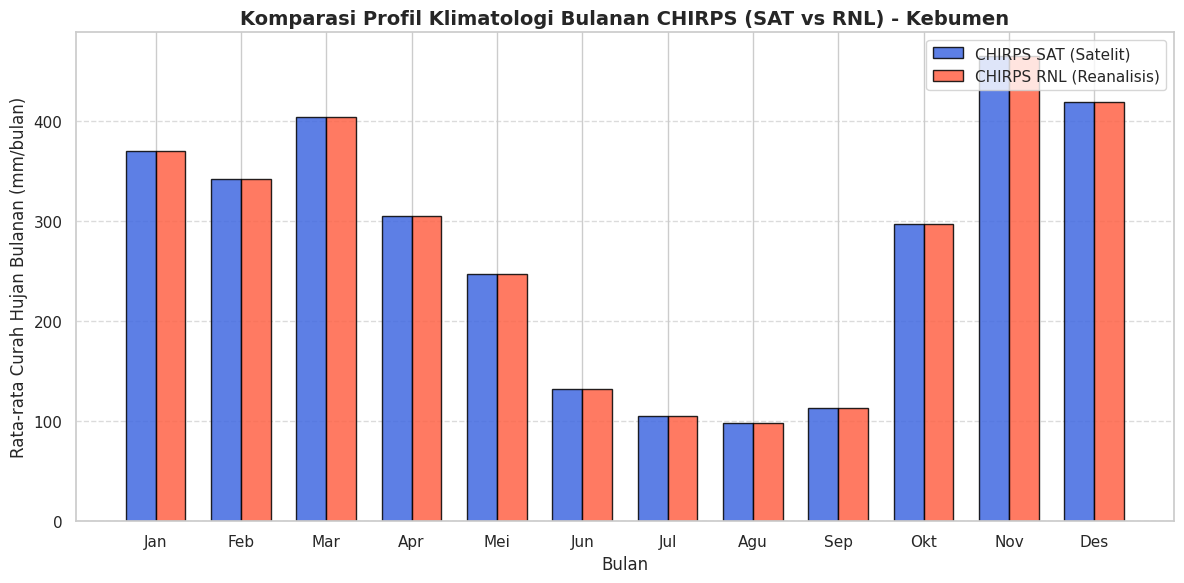

In [7]:
klim_sat = df_monthly['SAT'].groupby(df_monthly.index.month).mean()

plt.figure(figsize=(12, 6))
x_idx = np.arange(1, 13)
bar_w = 0.35

b1 = plt.bar(x_idx - bar_w/2, klim_sat, width=bar_w, label='CHIRPS SAT (Satelit)', color='royalblue', alpha=0.85, edgecolor='black')
if has_rnl:
    klim_rnl = df_monthly['RNL'].groupby(df_monthly.index.month).mean()
    b2 = plt.bar(x_idx + bar_w/2, klim_rnl, width=bar_w, label='CHIRPS RNL (Reanalisis)', color='tomato', alpha=0.85, edgecolor='black')

plt.title("Komparasi Profil Klimatologi Bulanan CHIRPS (SAT vs RNL) - Kebumen", fontsize=14, fontweight='bold')
plt.xlabel("Bulan", fontsize=12)
plt.ylabel("Rata-rata Curah Hujan Bulanan (mm/bulan)", fontsize=12)
plt.xticks(x_idx, ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des'])
plt.legend(loc='upper right', frameon=True)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig(out_dir / "klimatologi_komparasi_sat_vs_rnl.png", dpi=300, bbox_inches='tight')
plt.show()

## 7. Komparasi Distribusi Spasial (Kiri: SAT | Tengah: RNL | Kanan: Selisih SAT - RNL)

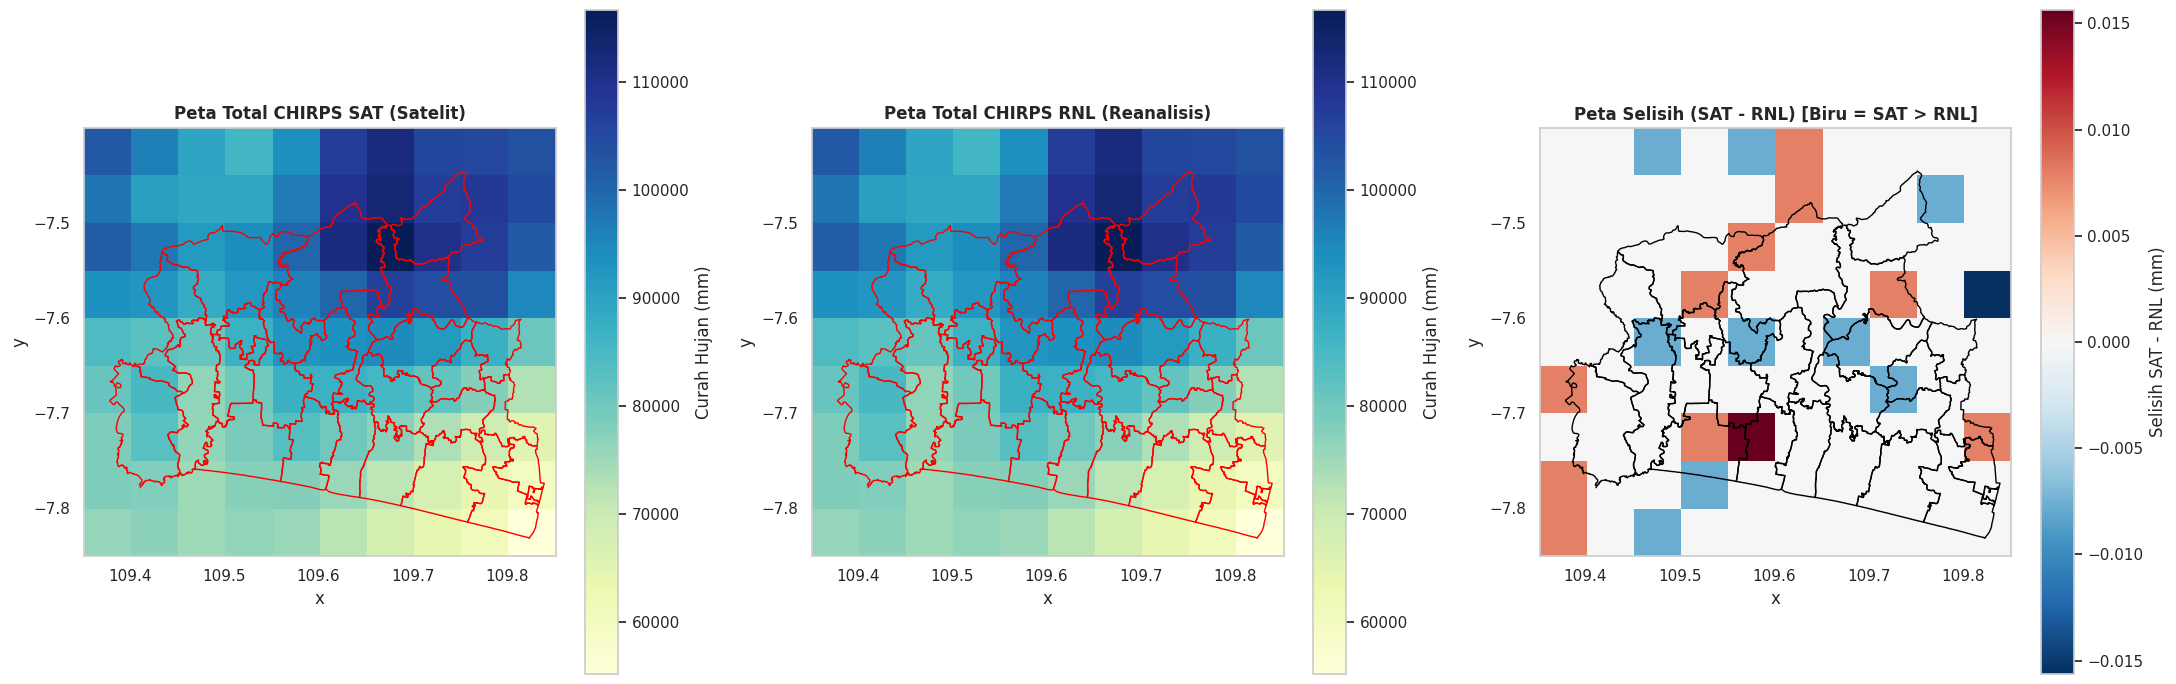

In [8]:
# Hitung total akumulasi spasial keseluruhan
total_sat = ds_sat['precipitation'].sum(dim='time')

if has_rnl:
    total_rnl = ds_rnl['precipitation'].sum(dim='time')
    diff_total = total_sat - total_rnl
    
    fig, axes = plt.subplots(1, 3, figsize=(22, 7))
    vmin = min(float(total_sat.min()), float(total_rnl.min()))
    vmax = max(float(total_sat.max()), float(total_rnl.max()))
    
    # 1. Peta SAT
    total_sat.plot(ax=axes[0], cmap='YlGnBu', vmin=vmin, vmax=vmax, cbar_kwargs={'label': 'Curah Hujan (mm)'})
    gdf_kec.boundary.plot(ax=axes[0], color='red', linewidth=1)
    axes[0].set_title("Peta Total CHIRPS SAT (Satelit)", fontsize=12, fontweight='bold')
    
    # 2. Peta RNL
    total_rnl.plot(ax=axes[1], cmap='YlGnBu', vmin=vmin, vmax=vmax, cbar_kwargs={'label': 'Curah Hujan (mm)'})
    gdf_kec.boundary.plot(ax=axes[1], color='red', linewidth=1)
    axes[1].set_title("Peta Total CHIRPS RNL (Reanalisis)", fontsize=12, fontweight='bold')
    
    # 3. Peta Selisih (SAT - RNL)
    max_diff = float(np.abs(diff_total).max())
    diff_total.plot(ax=axes[2], cmap='RdBu_r', vmin=-max_diff, vmax=max_diff, cbar_kwargs={'label': 'Selisih SAT - RNL (mm)'})
    gdf_kec.boundary.plot(ax=axes[2], color='black', linewidth=1)
    axes[2].set_title("Peta Selisih (SAT - RNL) [Biru = SAT > RNL]", fontsize=12, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(out_dir / "peta_total_komparasi_sat_vs_rnl.png", dpi=300, bbox_inches='tight')
    plt.show()

## 8. Peta Komparasi Spasial Bulanan dengan Normalisasi Diskret (Kiri: SAT | Kanan: RNL)
Visualisasi berdampingan (*side-by-side*) peta bulanan untuk tahun target dengan interval diskret ilmiah (`BoundaryNorm`) dan label kecamatan Kebumen.

In [9]:
def buat_cmap_diskret(bounds_list, nama_palette='YlGnBu'):
    base_cmap = plt.get_cmap(nama_palette)
    norm = mcolors.BoundaryNorm(boundaries=bounds_list, ncolors=base_cmap.N)
    return base_cmap, norm

interval_hujan = [0, 50, 100, 150, 200, 300, 400, 500, 600, 700, 800]
cmap_ilmiah, norm_ilmiah = buat_cmap_diskret(interval_hujan, 'YlGnBu')

minx, miny, maxx, maxy = gdf_kec.total_bounds
pad_x = (maxx - minx) * 0.04
pad_y = (maxy - miny) * 0.04

# Ambil seluruh tahun yang ada pada dataset yang dianalisis
available_years = sorted(pd.to_datetime(ds_sat.time.values).year.unique())
print(f"Tahun yang akan dipetakan ({len(available_years)} tahun): {available_years}")

total_saved = 0
for yr in available_years:
    # Buat subfolder per tahun di dalam folder output
    out_dir_year = out_dir / str(yr)
    out_dir_year.mkdir(parents=True, exist_ok=True)
    
    ds_sat_yr = ds_sat.sel(time=str(yr))
    monthly_sat = ds_sat_yr['precipitation'].groupby('time.month').sum()
    
    if has_rnl:
        ds_rnl_yr = ds_rnl.sel(time=str(yr))
        monthly_rnl = ds_rnl_yr['precipitation'].groupby('time.month').sum()
    
    months = monthly_sat.month.values
    
    for m in months:
        data_sat_m = monthly_sat.sel(month=m)
        
        if has_rnl and m in monthly_rnl.month.values:
            data_rnl_m = monthly_rnl.sel(month=m)
            fig, axes = plt.subplots(1, 2, figsize=(20, 10))
            
            # 1. Peta SAT (Kiri)
            im1 = data_sat_m.plot(ax=axes[0], cmap=cmap_ilmiah, norm=norm_ilmiah, add_colorbar=False)
            gdf_kec.boundary.plot(ax=axes[0], color='black', linewidth=0.7)
            for _, row in gdf_kec.iterrows():
                pt = row['geometry'].representative_point()
                col_nm = 'nm_kecamatan' if 'nm_kecamatan' in row else ('KECAMATAN' if 'KECAMATAN' in row else gdf_kec.columns[0])
                axes[0].annotate(row[col_nm], xy=(pt.x, pt.y), fontsize=7, fontweight='bold', ha='center', va='center',
                                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='black', linewidth=0.3, alpha=0.85))
            axes[0].set_xlim(minx - pad_x, maxx + pad_x)
            axes[0].set_ylim(miny - pad_y, maxy + pad_y)
            axes[0].set_title(f"CHIRPS v3 SAT (Satelit)\nBulan: {m:02d} Tahun: {yr}", fontsize=13, fontweight='bold')
            axes[0].set_xticks([]); axes[0].set_yticks([])
            
            # 2. Peta RNL (Kanan)
            im2 = data_rnl_m.plot(ax=axes[1], cmap=cmap_ilmiah, norm=norm_ilmiah, add_colorbar=False)
            gdf_kec.boundary.plot(ax=axes[1], color='black', linewidth=0.7)
            for _, row in gdf_kec.iterrows():
                pt = row['geometry'].representative_point()
                col_nm = 'nm_kecamatan' if 'nm_kecamatan' in row else ('KECAMATAN' if 'KECAMATAN' in row else gdf_kec.columns[0])
                axes[1].annotate(row[col_nm], xy=(pt.x, pt.y), fontsize=7, fontweight='bold', ha='center', va='center',
                                 bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='black', linewidth=0.3, alpha=0.85))
            axes[1].set_xlim(minx - pad_x, maxx + pad_x)
            axes[1].set_ylim(miny - pad_y, maxy + pad_y)
            axes[1].set_title(f"CHIRPS v3 RNL (Reanalisis)\nBulan: {m:02d} Tahun: {yr}", fontsize=13, fontweight='bold')
            axes[1].set_xticks([]); axes[1].set_yticks([])
            
            # Colorbar Tunggal Bersama di Bawah
            cbar = fig.colorbar(im1, ax=axes.ravel().tolist(), orientation='horizontal', pad=0.06, shrink=0.7, ticks=interval_hujan)
            cbar.set_label('Total Curah Hujan Bulanan (mm)', fontsize=11)
            
            png_path = out_dir_year / f"komparasi_chirps_sat_vs_rnl_{yr}_{m:02d}.png"
            fig.savefig(png_path, dpi=300, bbox_inches='tight')
            plt.close(fig)
            total_saved += 1
            
        else:
            # Single plot SAT jika RNL belum ada
            fig, ax = plt.subplots(figsize=(10, 10))
            im = data_sat_m.plot(ax=ax, cmap=cmap_ilmiah, norm=norm_ilmiah, add_colorbar=False)
            gdf_kec.boundary.plot(ax=ax, color='black', linewidth=0.7)
            for _, row in gdf_kec.iterrows():
                pt = row['geometry'].representative_point()
                col_nm = 'nm_kecamatan' if 'nm_kecamatan' in row else ('KECAMATAN' if 'KECAMATAN' in row else gdf_kec.columns[0])
                ax.annotate(row[col_nm], xy=(pt.x, pt.y), fontsize=7.5, fontweight='bold', ha='center', va='center',
                            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='black', linewidth=0.4, alpha=0.85))
            ax.set_xlim(minx - pad_x, maxx + pad_x)
            ax.set_ylim(miny - pad_y, maxy + pad_y)
            ax.set_title(f"Peta Akumulasi Curah Hujan CHIRPS SAT - Kebumen\nBulan: {m:02d} Tahun: {yr}", fontsize=13, fontweight='bold')
            ax.set_xticks([]); ax.set_yticks([])
            cbar = fig.colorbar(im, ax=ax, orientation='horizontal', pad=0.05, shrink=0.85, ticks=interval_hujan)
            cbar.set_label('Total Curah Hujan Bulanan (mm)', fontsize=11)
            png_path = out_dir_year / f"chirps_sat_{yr}_{m:02d}.png"
            fig.savefig(png_path, dpi=300, bbox_inches='tight')
            plt.close(fig)
            total_saved += 1
            
    print(f"  ✓ Selesai tahun {yr}: tersimpan di {out_dir_year}/")

print(f"\n🎉 Total {total_saved} file peta komparasi bulanan berhasil disimpan rapi ke subfolder tahunan di: {out_dir}")


Tahun yang akan dipetakan (27 tahun): [2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
  ✓ Selesai tahun 2000: tersimpan di /kaggle/working/chirps_komparasi/2000/
  ✓ Selesai tahun 2001: tersimpan di /kaggle/working/chirps_komparasi/2001/
  ✓ Selesai tahun 2002: tersimpan di /kaggle/working/chirps_komparasi/2002/
  ✓ Selesai tahun 2003: tersimpan di /kaggle/working/chirps_komparasi/2003/
  ✓ Selesai tahun 2004: tersimpan di /kaggle/working/chirps_komparasi/2004/
  ✓ Selesai tahun 2005: tersimpan di /kaggle/working/chirps_komparasi/2005/
  ✓ Selesai tahun 2006: tersimpan di /kaggle/working/chirps_komparasi/2006/
  ✓ Selesai tahun 2007: tersimpan di /kaggle/working/chirps_komparasi/2007/
  ✓ Selesai tahun 2008: tersimpan di /kaggle/working/chirps_komparasi/2008/
  ✓ Selesai tahun 2009: tersimpan di /kaggle/working/chirps_komparasi/2009/
  ✓ Selesai tahun 2010: tersimpan di /k